In [1]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [2]:
print("Dataset shape:", df.shape)

Dataset shape: (20640, 9)


In [3]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [4]:
print("\nSummary statistics:")
print(df.describe())


Summary statistics:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        

In [5]:
print("\nCorrelation with house value:")
print(
    df.corr(numeric_only=True)["MedHouseVal"]
    .sort_values(ascending=False)
)


Correlation with house value:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


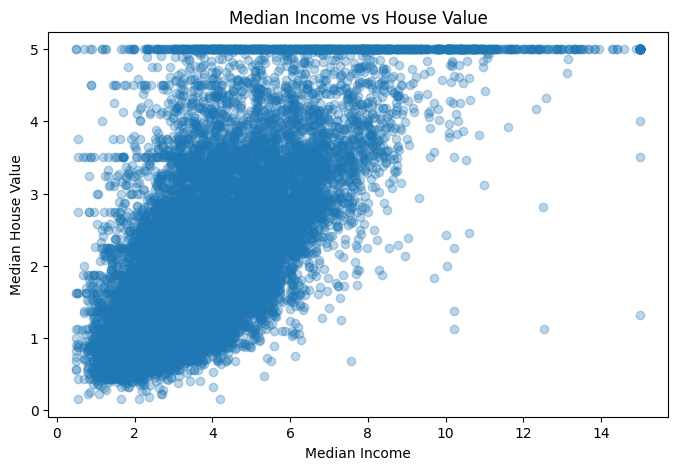

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.3
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs House Value")

plt.show()

As shown in the graph the MedValue increases as the MedInc generally increases showing strong correlation
except some of the values showing exceptional decrease in value despite their higher MedIncome.


In [7]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [8]:
print("\nDuplicate rows:", df.duplicated().sum())



Duplicate rows: 0


In [9]:
print("\nData types:")
print(df.dtypes)


Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


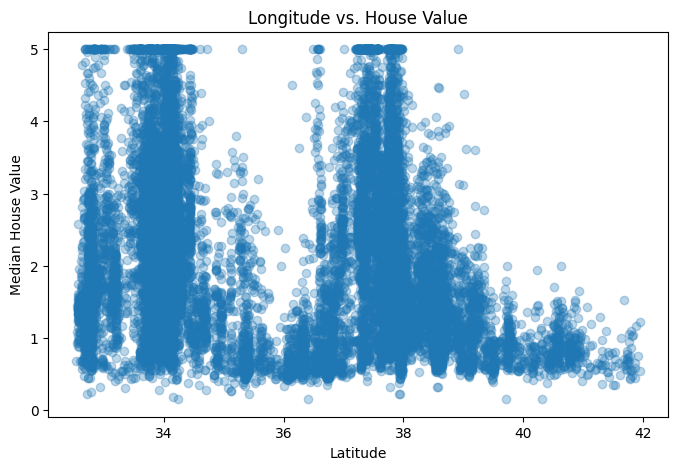

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Latitude"],
    df["MedHouseVal"],
    alpha=0.3
)

plt.xlabel("Latitude")
plt.ylabel("Median House Value")
plt.title("Longitude vs. House Value")

plt.show()

eventhought the mean of latitude make it look like it has a strong -ve relation with MedValue the graph ilustrates that the relation is a flactuating relation with no strong pattern


In [12]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training targets: (16512,)
Testing targets: (4128,)


In [14]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
import pandas as pd
# Predict house values using unseen test data
y_pred = model.predict(X_test)

# Compare actual values with predictions
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(comparison.head(10))

        Actual  Predicted
20046  0.47700   0.719123
3024   0.45800   1.764017
15663  5.00001   2.709659
20484  2.18600   2.838926
9814   2.78000   2.604657
13311  1.58700   2.011754
7113   1.98200   2.645500
7668   1.57500   2.168755
18246  3.40000   2.740746
5723   4.46600   3.915615


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.5332001304956555
MSE: 0.5558915986952442
RMSE: 0.7455813830127763
R²: 0.575787706032451


In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))
print("Baseline R²:", r2_score(y_test, baseline_pred))

Baseline MAE: 0.9060685490007149
Baseline R²: -0.00021908714592466794


In [18]:
from sklearn.metrics import r2_score

train_pred = model.predict(X_train)

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, y_pred))

Training R²: 0.6125511913966952
Testing R²: 0.575787706032451


In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

tree_model = DecisionTreeRegressor(
    max_depth=6,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Decision Tree MAE:", mean_absolute_error(y_test, tree_pred))
print("Decision Tree R²:", r2_score(y_test, tree_pred))

Decision Tree MAE: 0.5008044131156354
Decision Tree R²: 0.6205125146233951


In [20]:
tree_train_pred = tree_model.predict(X_train)

print("Decision Tree Training R²:", r2_score(y_train, tree_train_pred))
print("Decision Tree Testing R²:", r2_score(y_test, tree_pred))

Decision Tree Training R²: 0.6782454652473255
Decision Tree Testing R²: 0.6205125146233951


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest MAE:", mean_absolute_error(y_test, forest_pred))
print("Random Forest R²:", r2_score(y_test, forest_pred))

Random Forest MAE: 0.345891428680014
Random Forest R²: 0.7910821307887331


In [22]:
forest_train_pred = forest_model.predict(X_train)

print(
    "Random Forest Training R²:",
    r2_score(y_train, forest_train_pred)
)

print(
    "Random Forest Testing R²:",
    r2_score(y_test, forest_pred)
)

Random Forest Training R²: 0.919831491392645
Random Forest Testing R²: 0.7910821307887331


In [23]:
forest_model_8 = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

forest_model_8.fit(X_train, y_train)

forest_pred_8 = forest_model_8.predict(X_test)

print("Training R²:", r2_score(y_train, forest_model_8.predict(X_train)))
print("Testing R²:", r2_score(y_test, forest_pred_8))
print("Testing MAE:", mean_absolute_error(y_test, forest_pred_8))

Training R²: 0.8051179656475965
Testing R²: 0.7383685168658252
Testing MAE: 0.40259867157206397


In [24]:
forest_model_10 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

forest_model_10.fit(X_train, y_train)

forest_pred_10 = forest_model_10.predict(X_test)

print("Training R²:", r2_score(y_train, forest_model_10.predict(X_train)))
print("Testing R²:", r2_score(y_test, forest_pred_10))
print("Testing MAE:", mean_absolute_error(y_test, forest_pred_10))

Training R²: 0.8719309582356174
Testing R²: 0.7737402686595128
Testing MAE: 0.36628896132800176


In [25]:
import pandas as pd

importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

MedInc        0.560724
AveOccup      0.139083
Latitude      0.083760
Longitude     0.083498
HouseAge      0.050388
AveRooms      0.037246
Population    0.022905
AveBedrms     0.022395
dtype: float64


In [26]:
residuals = y_test - forest_pred

print(residuals.describe())

count    4128.000000
mean       -0.006769
std         0.523248
min        -2.839219
25%        -0.252881
50%        -0.055660
75%         0.169736
max         3.160111
Name: MedHouseVal, dtype: float64


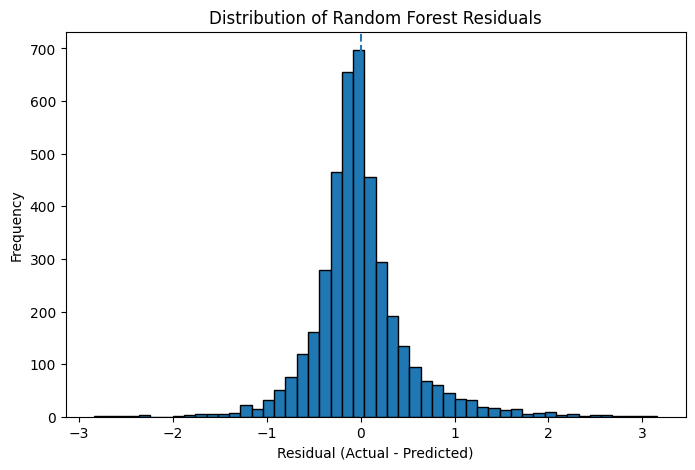

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Random Forest Residuals")
plt.show()

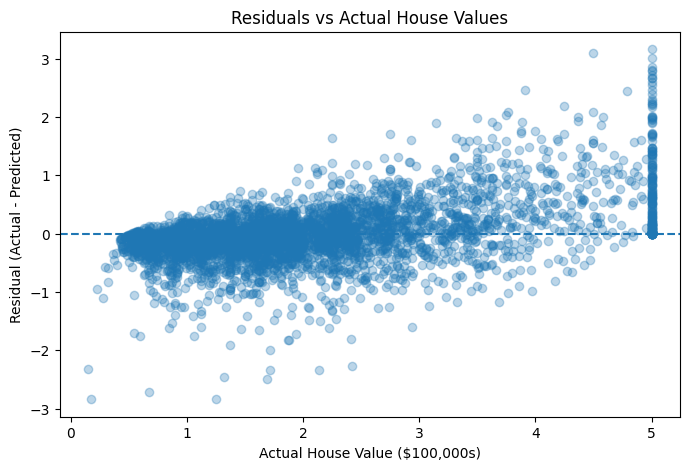

In [28]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, residuals, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Actual House Value ($100,000s)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Actual House Values")
plt.show()

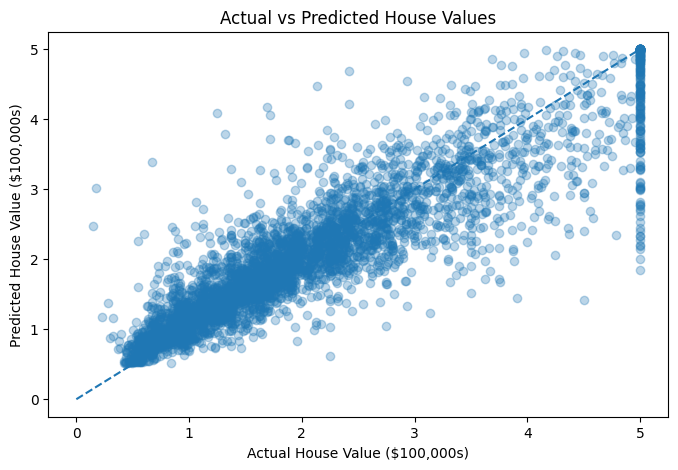

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, forest_pred, alpha=0.3)
plt.plot([0, 5], [0, 5], linestyle="--")
plt.xlabel("Actual House Value ($100,000s)")
plt.ylabel("Predicted House Value ($100,000s)")
plt.title("Actual vs Predicted House Values")
plt.show()

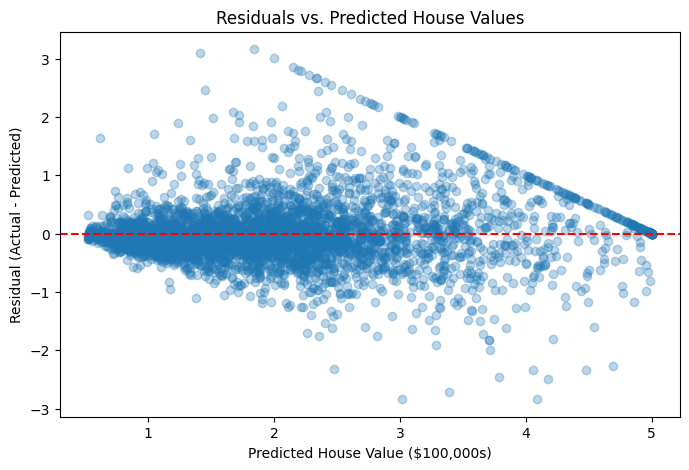

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(forest_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Value ($100,000s)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs. Predicted House Values")

plt.show()

In [31]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": forest_pred,
    "Residual": residuals
})

results["PriceRange"] = pd.cut(
    results["Actual"],
    bins=[0, 1, 2, 3, 4, 5.01],
    labels=["0–1", "1–2", "2–3", "3–4", "4–5"]
)

results.groupby("PriceRange", observed=True).agg(
    Count=("Residual", "count"),
    MeanResidual=("Residual", "mean"),
    MAE=("Residual", lambda x: x.abs().mean()),
    ResidualStd=("Residual", "std")
).round(3)

,Count,MeanResidual,MAE,ResidualStd
PriceRange,,,,
0–1,739,-0.227,0.250,0.309
1–2,1682,-0.146,0.257,0.350
2–3,956,0.022,0.350,0.470
3–4,412,0.292,0.530,0.628
4–5,339,0.720,0.761,0.760


In [32]:
# Count test houses whose target value is exactly $500,000
cap_mask = y_test.eq(5.0)

print("Houses at the $500,000 cap:", int(cap_mask.sum()))
print("Percentage at the cap:", round(cap_mask.mean() * 100, 2), "%")

Houses at the $500,000 cap: 5
Percentage at the cap: 0.12 %


In [33]:
cap_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": forest_pred,
    "Residual": residuals
})

cap_results["AtCap"] = cap_results["Actual"].eq(5.0)

comparison = cap_results.groupby("AtCap").agg(
    Count=("Residual", "size"),
    MeanResidual=("Residual", "mean"),
    MAE=("Residual", lambda x: x.abs().mean())
).round(3)

print(comparison)

       Count  MeanResidual    MAE
AtCap                            
False   4123        -0.008  0.345
True       5         0.757  0.757


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

for leaf_size in [1, 5, 10]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=leaf_size,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\nmin_samples_leaf = {leaf_size}")
    print("Training R²:", round(r2_score(y_train, train_pred), 3))
    print("Testing R²:", round(r2_score(y_test, test_pred), 3))
    print("Testing MAE:", round(mean_absolute_error(y_test, test_pred), 3))


min_samples_leaf = 1
Training R²: 0.92
Testing R²: 0.791
Testing MAE: 0.346

min_samples_leaf = 5
Training R²: 0.888
Testing R²: 0.79
Testing MAE: 0.345

min_samples_leaf = 10
Training R²: 0.859
Testing R²: 0.782
Testing MAE: 0.351


In [35]:
for n_trees in [100, 200, 300]:

    model = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=12,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\nn_estimators = {n_trees}")
    print("Training R²:", round(r2_score(y_train, train_pred), 3))
    print("Testing R²:", round(r2_score(y_test, test_pred), 3))
    print("Testing MAE:", round(mean_absolute_error(y_test, test_pred), 3))


n_estimators = 100
Training R²: 0.92
Testing R²: 0.791
Testing MAE: 0.346

n_estimators = 200
Training R²: 0.92
Testing R²: 0.792
Testing MAE: 0.346

n_estimators = 300
Training R²: 0.92
Testing R²: 0.792
Testing MAE: 0.346


In [36]:
print(X_train[["AveRooms", "AveBedrms"]].describe())

           AveRooms     AveBedrms
count  16512.000000  16512.000000
mean       5.435235      1.096685
std        2.387375      0.433215
min        0.888889      0.333333
25%        4.452055      1.006508
50%        5.235874      1.049286
75%        6.061037      1.100348
max      141.909091     25.636364


In [37]:
# Create the new feature
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

X_train_fe["BedroomRatio"] = (
    X_train_fe["AveBedrms"] / X_train_fe["AveRooms"]
)

X_test_fe["BedroomRatio"] = (
    X_test_fe["AveBedrms"] / X_test_fe["AveRooms"]
)

# Inspect the new feature
print(X_train_fe["BedroomRatio"].describe())

count    16512.000000
mean         0.212858
std          0.057995
min          0.100000
25%          0.175178
50%          0.202808
75%          0.239501
max          1.000000
Name: BedroomRatio, dtype: float64


In [38]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Model 1: Original features
original_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

original_model.fit(X_train, y_train)
original_pred = original_model.predict(X_test)

# Model 2: Original features + BedroomRatio
feature_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

feature_model.fit(X_train_fe, y_train)
feature_pred = feature_model.predict(X_test_fe)

# Compare performance
print("ORIGINAL MODEL")
print("Test R²:", round(r2_score(y_test, original_pred), 4))
print("Test MAE:", round(mean_absolute_error(y_test, original_pred), 4))

print("\nMODEL WITH BEDROOM RATIO")
print("Test R²:", round(r2_score(y_test, feature_pred), 4))
print("Test MAE:", round(mean_absolute_error(y_test, feature_pred), 4))

ORIGINAL MODEL
Test R²: 0.792
Test MAE: 0.3456

MODEL WITH BEDROOM RATIO
Test R²: 0.7916
Test MAE: 0.346


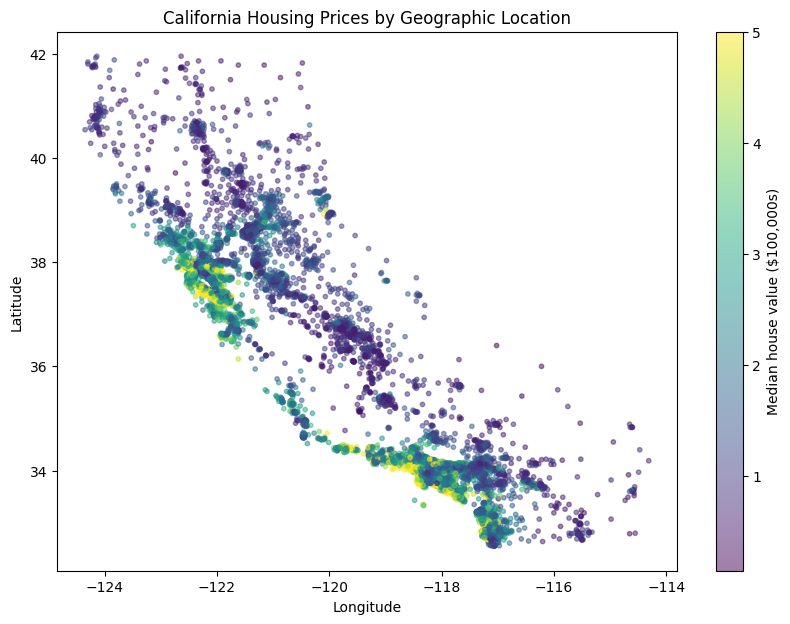

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train["Longitude"],
    X_train["Latitude"],
    c=y_train,
    cmap="viridis",
    alpha=0.5,
    s=10
)

plt.colorbar(scatter, label="Median house value ($100,000s)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Housing Prices by Geographic Location")
plt.show()

In [40]:
import pandas as pd

importance = pd.Series(
    original_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

MedInc        0.561734
AveOccup      0.138760
Latitude      0.083456
Longitude     0.083070
HouseAge      0.050257
AveRooms      0.037210
Population    0.023093
AveBedrms     0.022418
dtype: float64


In [41]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

boost_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

boost_model.fit(X_train, y_train)
boost_pred = boost_model.predict(X_test)

print("Gradient Boosting R²:", round(r2_score(y_test, boost_pred), 4))
print("Gradient Boosting MAE:", round(mean_absolute_error(y_test, boost_pred), 4))

Gradient Boosting R²: 0.845
Gradient Boosting MAE: 0.2984


In [42]:
# Evaluate Gradient Boosting on training data
boost_train_pred = boost_model.predict(X_train)

train_r2 = r2_score(y_train, boost_train_pred)
test_r2 = r2_score(y_test, boost_pred)

train_mae = mean_absolute_error(y_train, boost_train_pred)
test_mae = mean_absolute_error(y_test, boost_pred)

print("Training R²:", round(train_r2, 4))
print("Testing R²:", round(test_r2, 4))

print("Training MAE:", round(train_mae, 4))
print("Testing MAE:", round(test_mae, 4))

Training R²: 0.9082
Testing R²: 0.845
Training MAE: 0.2403
Testing MAE: 0.2984


In [43]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

for iterations in [100, 200, 300, 500]:
    model = HistGradientBoostingRegressor(
        max_iter=iterations,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\nIterations: {iterations}")
    print("Training R²:", round(r2_score(y_train, train_pred), 4))
    print("Testing R²:", round(r2_score(y_test, test_pred), 4))
    print("Testing MAE:", round(mean_absolute_error(y_test, test_pred), 4))


Iterations: 100
Training R²: 0.8805
Testing R²: 0.8355
Testing MAE: 0.3096

Iterations: 200
Training R²: 0.9082
Testing R²: 0.845
Testing MAE: 0.2984

Iterations: 300
Training R²: 0.9242
Testing R²: 0.8478
Testing MAE: 0.2945

Iterations: 500
Training R²: 0.9252
Testing R²: 0.8481
Testing MAE: 0.2941


In [44]:
from sklearn.ensemble import HistGradientBoostingRegressor

final_model = HistGradientBoostingRegressor(
    max_iter=500,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

final_model.fit(X_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",500
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 